In [2]:
# 웹 서버 접속 로그 생성 (가상) — 한 줄이 통째로 문자열
%pip install polars memory_profiler psutil
import numpy as np
import pandas as pd
import polars as pl
import time
import gc


np.random.seed(7)
n_logs = 1500
ips = [f"203.0.113.{k}" for k in range(1, 60)] + [f"198.51.100.{k}" for k in range(1, 60)]
paths = ["/", "/products", "/products/123", "/products/456", "/cart",
         "/checkout", "/login", "/search", "/api/orders"]
methods = ["GET", "GET", "GET", "POST"]
statuses = [200, 200, 200, 200, 200, 404, 500, 301]

# 시각: 7일치, 초 단위로 무작위 발생 후 정렬
log_times = pd.to_datetime("2025-03-01") + pd.to_timedelta(
    np.sort(np.random.randint(0, 7 * 24 * 3600, n_logs)), unit="s")

lines = []
for i in range(n_logs):
    ip = np.random.choice(ips)
    ts_str = log_times[i].strftime("%d/%b/%Y:%H:%M:%S")   # 12/Jan/2025:10:15:32
    m = np.random.choice(methods)
    p = np.random.choice(paths)
    st = np.random.choice(statuses)
    sz = np.random.randint(200, 5000)
    lines.append(f'{ip} - - [{ts_str}] "{m} {p} HTTP/1.1" {st} {sz}')

web_logs = pd.DataFrame({"raw": lines})
print("웹 로그 생성 완료:", web_logs.shape)
print("\n[원본 로그 한 줄은 이렇게 생겼습니다]")
for line in web_logs["raw"].head(3):
    print(line)

Note: you may need to restart the kernel to use updated packages.
웹 로그 생성 완료: (1500, 1)

[원본 로그 한 줄은 이렇게 생겼습니다]
203.0.113.39 - - [01/Mar/2025:00:01:14] "GET / HTTP/1.1" 200 2371
198.51.100.21 - - [01/Mar/2025:00:02:24] "GET / HTTP/1.1" 301 284
198.51.100.17 - - [01/Mar/2025:00:02:28] "GET /search HTTP/1.1" 200 1448


In [3]:
# ============================================
# 시나리오 1 — 정규식으로 6개 필드를 한 번에 추출
# ============================================
pattern = (
    r"(?P<ip>\d+\.\d+\.\d+\.\d+)"        # IP: 숫자.숫자.숫자.숫자
    r" - - \["                            # 고정 구분 부분
    r"(?P<ts>[^\]]+)"                     # 시각: ] 가 아닌 글자들
    r"\] \""                              # ] 와 따옴표
    r"(?P<method>\w+) "                   # 방식: GET/POST
    r"(?P<path>\S+)"                      # 경로: 공백 아닌 글자들
    r"[^\"]*\" "                          # HTTP/1.1 부분 건너뛰기
    r"(?P<status>\d+) "                   # 상태 코드
    r"(?P<size>\d+)"                      # 응답 크기
)
logs = web_logs["raw"].str.extract(pattern)
print("\n추출된 표:", logs.shape)
print(logs.head())
print("\n추출 실패(어느 한 칸이라도 NaN) 행 수:", logs.isna().any(axis=1).sum())


추출된 표: (1500, 6)
              ip                    ts method       path status  size
0   203.0.113.39  01/Mar/2025:00:01:14    GET          /    200  2371
1  198.51.100.21  01/Mar/2025:00:02:24    GET          /    301   284
2  198.51.100.17  01/Mar/2025:00:02:28    GET    /search    200  1448
3   203.0.113.35  01/Mar/2025:00:03:56    GET      /cart    404  3921
4   203.0.113.47  01/Mar/2025:00:14:29    GET  /products    500  2580

추출 실패(어느 한 칸이라도 NaN) 행 수: 0


In [4]:
# ============================================
# 시나리오 2 — 타입 정리(날짜·숫자) + dt 부품
# ============================================
logs["ts"] = pd.to_datetime(logs["ts"], format="%d/%b/%Y:%H:%M:%S", errors="coerce")
logs["status"] = logs["status"].astype(int)
logs["size"] = logs["size"].astype(int)
 
# 날짜 파싱 실패 확인 (errors="coerce" → 실패하면 NaT)
print("\n날짜 파싱 실패 건수:", logs["ts"].isna().sum())
print("기간:", logs["ts"].min(), "~", logs["ts"].max())
 
# dt 부품: 시각(hour)과 요일
logs["hour"] = logs["ts"].dt.hour
logs["dow_name"] = logs["ts"].dt.day_name()
 
print("\n정리 후 자료형:")
print(logs.dtypes)
print()
print(logs[["ip", "ts", "method", "path", "status", "hour", "dow_name"]].head())


날짜 파싱 실패 건수: 0
기간: 2025-03-01 00:01:14 ~ 2025-03-07 23:42:41

정리 후 자료형:
ip                     str
ts          datetime64[us]
method                 str
path                   str
status               int64
size                 int64
hour                 int32
dow_name               str
dtype: object

              ip                  ts method       path  status  hour  dow_name
0   203.0.113.39 2025-03-01 00:01:14    GET          /     200     0  Saturday
1  198.51.100.21 2025-03-01 00:02:24    GET          /     301     0  Saturday
2  198.51.100.17 2025-03-01 00:02:28    GET    /search     200     0  Saturday
3   203.0.113.35 2025-03-01 00:03:56    GET      /cart     404     0  Saturday
4   203.0.113.47 2025-03-01 00:14:29    GET  /products     500     0  Saturday


In [5]:
# ============================================
# 시나리오 2 — 상태 코드·인기 경로 빠르게 집계
# ============================================
print("\n[상태 코드 분포]")
print(logs["status"].value_counts())
 
error_rate = (logs["status"] >= 400).mean() * 100   # 4xx·5xx 비율
print(f"\n오류 응답(4xx·5xx) 비율: {error_rate:.1f}%")
 
print("\n[요청이 많은 경로 TOP 5]")
print(logs["path"].value_counts().head())


[상태 코드 분포]
status
200    964
301    188
404    178
500    170
Name: count, dtype: int64

오류 응답(4xx·5xx) 비율: 23.2%

[요청이 많은 경로 TOP 5]
path
/                184
/search          175
/cart            173
/products/456    171
/products        168
Name: count, dtype: int64


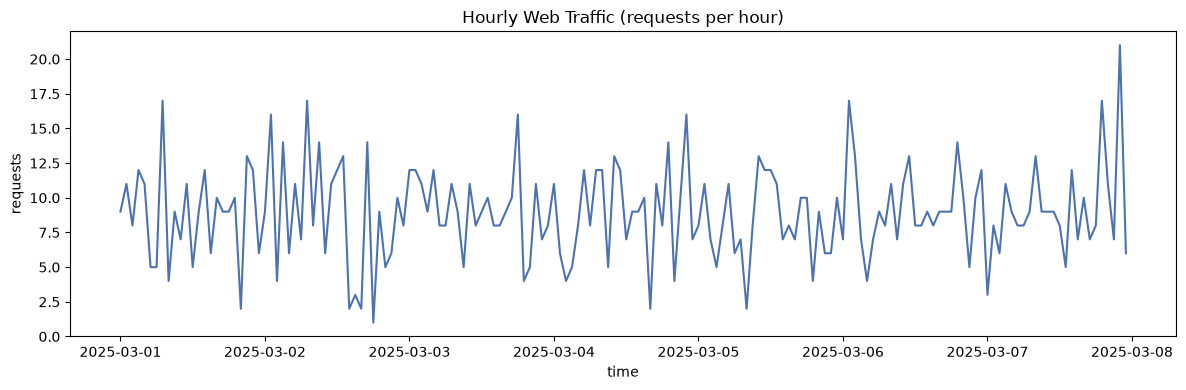


가장 트래픽이 많았던 시간대 TOP 3:
ts
2025-03-07 22:00:00    21
2025-03-01 07:00:00    17
2025-03-06 01:00:00    17
Name: ip, dtype: int64
시간당 평균 요청 수: 8.9건


In [8]:
# ============================================
# 시나리오 3 — 시간대별 트래픽 (resample 'h')
# ============================================

import matplotlib.pyplot as plt
log_ts = logs.dropna(subset=["ts"]).set_index("ts").sort_index()
hourly_traffic = log_ts["ip"].resample("h").count()    # 시간당 요청 수
 
plt.figure(figsize=(12, 4))
plt.plot(hourly_traffic.index, hourly_traffic.values, color="#4C72B0")
plt.title("Hourly Web Traffic (requests per hour)")
plt.xlabel("time"); plt.ylabel("requests")
plt.tight_layout(); plt.show()
 
print("\n가장 트래픽이 많았던 시간대 TOP 3:")
print(hourly_traffic.sort_values(ascending=False).head(3))
print(f"시간당 평균 요청 수: {hourly_traffic.mean():.1f}건")
 

In [9]:
# ============================================
# 시나리오 4 — 다음 분석 제안의 근거 만들기
# ============================================
 
# --- 제안 1: 구매 흐름 경로의 오류 ---
# (1) 경로별 오류율: True/False 평균 = 오류 비율
logs["is_error"] = logs["status"] >= 400
path_err = (logs.groupby("path")["is_error"].mean()
                .mul(100).round(1)
                .sort_values(ascending=False))
print("\n[경로별 오류율 (%)]")
print(path_err)
 
# (2) 경로 × 상태 코드 교차표: 어떤 오류가 몇 건인지
status_by_path = pd.crosstab(logs["path"], logs["status"])
print("\n[경로별 상태 코드 건수]")
print(status_by_path)
 
print("\n404가 가장 많은 경로:", status_by_path[404].idxmax(), f"({status_by_path[404].max()}건)")
print("500이 가장 많은 경로:", status_by_path[500].idxmax(), f"({status_by_path[500].max()}건)")
 
# --- 제안 2: IP별 요청 수 ---
ip_counts = logs["ip"].value_counts()
print(f"\n[IP별 요청 수] 접속 IP {ip_counts.size}개 / 최다 {ip_counts.max()}건 / 평균 {ip_counts.mean():.1f}건")
print(ip_counts.head())


[경로별 오류율 (%)]
path
/checkout        28.0
/products/456    25.1
/cart            24.9
/                23.9
/api/orders      23.8
/login           23.0
/products        22.6
/products/123    18.9
/search          18.3
Name: is_error, dtype: float64

[경로별 상태 코드 건수]
status         200  301  404  500
path                             
/              115   25   20   24
/api/orders    104   24   22   18
/cart          115   15   17   26
/checkout       99   17   28   17
/login          91   26   21   14
/products      104   26   17   21
/products/123   98   22   11   17
/products/456  112   16   24   19
/search        126   17   18   14

404가 가장 많은 경로: /checkout (28건)
500이 가장 많은 경로: /cart (26건)

[IP별 요청 수] 접속 IP 118개 / 최다 24건 / 평균 12.7건
ip
198.51.100.41    24
203.0.113.58     21
198.51.100.52    19
203.0.113.27     19
203.0.113.18     19
Name: count, dtype: int64


### 1. 데이터 개요
- 로그 줄 수: 1500 줄
- 기간: 2025-03-01 ~ 2025-03-07
- 추출 필드: ip, ts, method, path, status, size

### 2. 파싱 (어떻게 표로 만들었나)
- 사용한 정규식 패턴의 핵심: IP는 `\d+\.\d+...`, 시각은 `[^\]]+` 로 추출
- 날짜 형식: %d/%b/%Y:%H:%M:%S 로 파싱, 실패 0건

### 3. 트래픽 요약
- 총 요청 수: 1500 건
- 오류 응답(4xx·5xx) 비율: 23.2%
- 요청 많은 경로 TOP 3: /, /search, /cart

### 4. 시간 패턴 (리샘플링에서 읽은 것)
- 트래픽이 가장 몰린 시간대: 2025-03-07 오후 10시
- 요일/시간대 특징: 요일/시간대별로 차이가 거의 없다.

### 5. 다음 분석 제안
- 1. 구매 흐름 경로의 오류 원인 점검
   - /checkout은 오류율이 28.0%로 가장 높고 대부분 404(28건)였다.
   - /cart는 500 오류가 26건으로 경로 중 가장 많았다.
   - 두 경로 모두 장바구니 → 결제로 이어지는 구매 흐름에 있어, 오류가 매출 손실로 이어질 수 있다.
   → 다음에는 두 경로의 오류가 특정 날짜·시간대에 몰렸는지 확인해, 일시적인 장애인지 계속되는 문제인지 구분한다.

2. 비정상 접근 IP 탐지
   - 전체 요청 수 기준으로는 눈에 띄는 IP가 없었다 (최다 24건, 평균 약 13건).
   → 다음에는 10분 단위로 IP별 요청 수를 세어, 짧은 시간에 몰린 접근이 있는지 확인한다.